--- Mức nhiễu = 1.0 ---
Intercept: 4.15 | Slope: 2.79
MSE: 0.73 | R^2 score: 0.7380

--- Mức nhiễu = 3.0 ---
Intercept: 3.69 | Slope: 3.15
MSE: 6.88 | R^2 score: 0.1827

--- Mức nhiễu = 6.0 ---
Intercept: 2.80 | Slope: 3.26
MSE: 32.88 | R^2 score: 0.1230



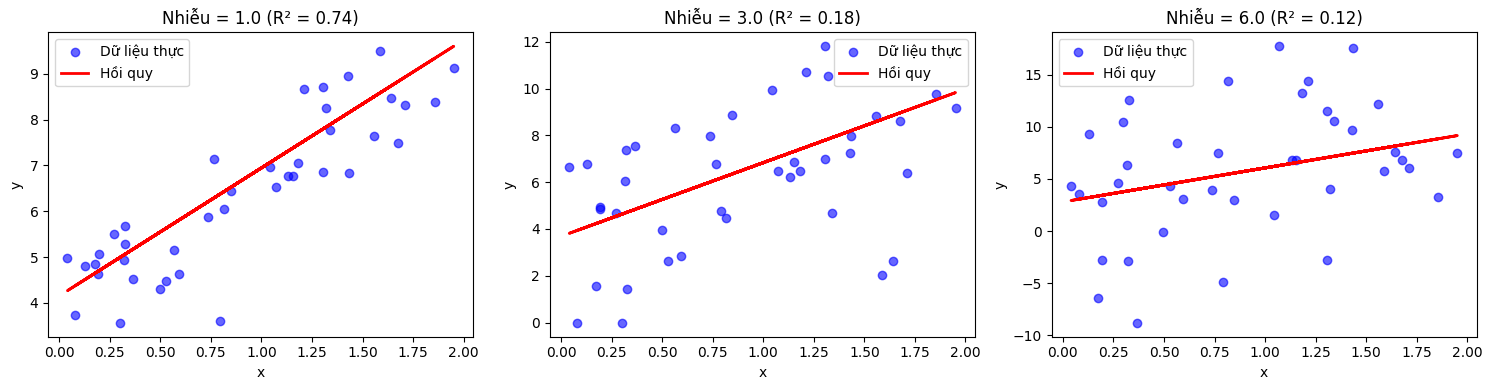

In [17]:
#Bai 1
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0)
x = 2 * np.random.rand(200, 1)

# Thử nghiệm với 3 mức độ nhiễu tăng dần
muc_nhieu = [1.0, 3.0, 6.0]

plt.figure(figsize=(15, 4))

for i, noise in enumerate(muc_nhieu):
    # Sinh dữ liệu y với mức nhiễu tương ứng
    y = 4 + 3 * x + noise * np.random.randn(200, 1)

    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"--- Mức nhiễu = {noise} ---")
    print(f"Intercept: {model.intercept_[0]:.2f} | Slope: {model.coef_[0][0]:.2f}")
    print(f"MSE: {mse:.2f} | R^2 score: {r2:.4f}\n")

    # Vẽ biểu đồ so sánh
    plt.subplot(1, 3, i + 1)
    plt.scatter(x_test, y_test, color="blue", alpha=0.6, label="Dữ liệu thực")
    plt.plot(x_test, y_pred, color="red", linewidth=2, label="Hồi quy")
    plt.title(f"Nhiễu = {noise} (R² = {r2:.2f})")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()

plt.tight_layout()
plt.show()

In [18]:
#Bai 2
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

# Tạo dữ liệu giả lập (Bài toán BMI - Mắc bệnh)
np.random.seed(42)
X = 15 + 25 * np.random.rand(300, 1)
prob = 1 / (1 + np.exp(-0.5 * (X - 27) + np.random.randn(300, 1)))
y = (prob >= 0.5).astype(int).ravel()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Huấn luyện mô hình
model = LogisticRegression()
model.fit(X_train, y_train)

# Lấy xác suất dự đoán thuộc lớp 1 (Mắc bệnh)
y_prob = model.predict_proba(X_test)[:, 1]

# Thử nghiệm với các ngưỡng khác nhau: 0.5, 0.6, 0.7
nguong_list = [0.5, 0.6, 0.7]

for threshold in nguong_list:
    # Áp dụng ngưỡng mới để phân loại nhãn 0 hoặc 1
    y_pred_custom = (y_prob >= threshold).astype(int)

    acc = accuracy_score(y_test, y_pred_custom)
    prec = precision_score(y_test, y_pred_custom, zero_division=0)
    rec = recall_score(y_test, y_pred_custom, zero_division=0)
    cm = confusion_matrix(y_test, y_pred_custom)

    print(f"=== NGƯỠNG DỰ ĐOÁN = {threshold} ===")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")
    print("Ma trận nhầm lẫn:")
    print(cm)
    print()

=== NGƯỠNG DỰ ĐOÁN = 0.5 ===
Accuracy: 0.9833 | Precision: 0.9697 | Recall: 1.0000
Ma trận nhầm lẫn:
[[27  1]
 [ 0 32]]

=== NGƯỠNG DỰ ĐOÁN = 0.6 ===
Accuracy: 0.9500 | Precision: 0.9677 | Recall: 0.9375
Ma trận nhầm lẫn:
[[27  1]
 [ 2 30]]

=== NGƯỠNG DỰ ĐOÁN = 0.7 ===
Accuracy: 0.9167 | Precision: 0.9655 | Recall: 0.8750
Ma trận nhầm lẫn:
[[27  1]
 [ 4 28]]



--- 5 DÒNG ĐẦU CỦA TẬP DỮ LIỆU BOSTON HOUSING ---
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0  296.0   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0  242.0   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0  242.0   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0  222.0   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH BOSTON HOUSING ---
Hệ số chặn (Intercept): 30.2468
Mean Squared Error (MSE): 24.2911
R^2 score: 0.6688


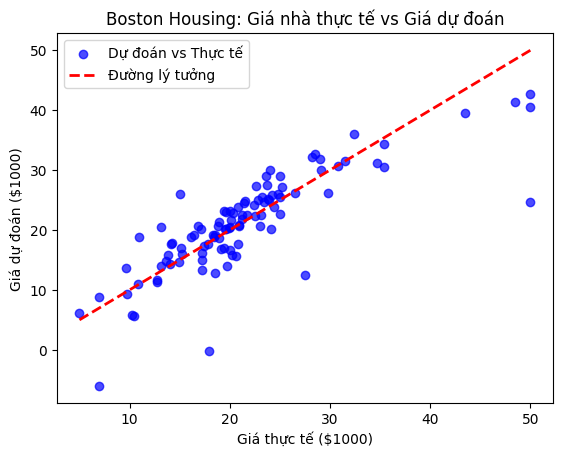

In [19]:
#Bai 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải tập dữ liệu Boston Housing
boston = fetch_openml(name="boston", version=1, as_frame=True, parser="auto")
df = boston.frame

# Chuyển toàn bộ dữ liệu sang kiểu số thực (float) để tránh lỗi định dạng category
df = df.astype(float)

print("--- 5 DÒNG ĐẦU CỦA TẬP DỮ LIỆU BOSTON HOUSING ---")
print(df.head())

# Tách biến đầu vào X (13 thuộc tính) và biến mục tiêu y (MEDV - Giá nhà trung bình, đơn vị: $1000)
X = df.drop(columns=['MEDV'])
y = df['MEDV']

# 2. Phân chia dữ liệu: 80% huấn luyện, 20% kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Huấn luyện mô hình Linear Regression và dự đoán
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 4. Tính toán các chỉ số đánh giá MSE và R^2 score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH BOSTON HOUSING ---")
print(f"Hệ số chặn (Intercept): {model.intercept_:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R^2 score: {r2:.4f}")

# Vẽ biểu đồ so sánh giá thực tế và giá dự đoán
plt.scatter(y_test, y_pred, color="blue", alpha=0.7, label="Dự đoán vs Thực tế")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--", linewidth=2, label="Đường lý tưởng")
plt.title("Boston Housing: Giá nhà thực tế vs Giá dự đoán")
plt.xlabel("Giá thực tế ($1000)")
plt.ylabel("Giá dự đoán ($1000)")
plt.legend()
plt.show()